# Notebook 5: Answer-Convergence Early Exit for Soft Thinking

**Course project: Foundations of LLMs (AI60213)** · Base paper: *Soft Thinking* (Zhang et al., NeurIPS 2025)

Notebook 3 found that Soft Thinking at 1.7B **overthinks**: on correct training traces, about 60% of thinking happens *after* the correct answer has already been written. It also found that the paper's entropy-based Cold Stop cannot recover that waste, because its token savings and its harm grow together. This notebook tests an **answer-aware** stopping rule instead.

**Contents**

0. Briefing
1. Setup, including the saved traces of Notebooks 1–4
2. Shared machinery (identical to Notebooks 1–4)
3. Answer probes and exact replay
4. Evaluation on every set of saved traces
5. Comparison and the combined result
6. Conclusion

---
# Part 0: Briefing

## 0.1 The rule (fixed before running)

Every **128 thinking steps** we briefly ask the model for its current answer:

1. Append `</think>\n\nThe final answer is \boxed{` to the thinking so far.
2. Greedy-decode up to 12 tokens, up to the closing `}`.
3. **Discard** these probe tokens; they never enter the real trace.

If the **last 2 probes give the same number**, thinking stops at that point and the model writes its final answer exactly as in Notebooks 1–4: `</think>\n\n`, then greedy decoding. Otherwise thinking continues unchanged.

This is the *answer convergence* idea from chain-of-thought reasoning ([Liu & Wang, 2025, arXiv:2506.02536](https://arxiv.org/abs/2506.02536); related: DEER, [Yang et al., 2025, arXiv:2504.15895](https://arxiv.org/abs/2504.15895)), applied here to Soft Thinking, where the thinking consists of concept tokens. It is training-free and uses no labels.

**Main rule:** probe every 128 steps, stop after 2 matching answers. It is fixed in advance and is the only rule used for the headline result. Three other rules (every 64 / 2 matches, every 128 / 3 matches, every 256 / 2 matches) are reported as a **sensitivity analysis**, not used for selection.

## 0.2 Exact replay instead of re-decoding

Decoding is deterministic; Notebook 3 verified that replayed cut points match a real rerun on 100% of questions. Up to the exit point, a run with early exit is therefore **identical** to the saved trace. So for each saved trace we:

1. Rebuild exactly what the model was fed, with one forward pass.
2. Run **all probes in parallel**, each attending only to the thinking before its checkpoint, with the same probe-mask technique as the diagnosis. A check cell compares this against brute-force decoding.
3. Find the exit point under each rule.
4. **Generate the real final answer** from the exit point. Questions that never exit keep their original answer.

So every reported accuracy comes from an answer the model actually generated, not from a proxy.

## 0.3 Accounting

* **Thinking tokens:** concept tokens fed before thinking ends.
* **Probe overhead:** the probe prompt plus decoded probe tokens, summed over the probes made up to the exit (or over all probes if the question never exits). We report thinking tokens both without and with this overhead.

## 0.4 Evaluated traces

Every set of saved traces from the project can be evaluated; each has a switch in the config.

| Traces | Source | Questions | Default |
|---|---|---|---|
| Soft Thinking (paper), test | Notebook 1 | 250 | on |
| Soft Thinking (paper), training questions (more data; the rule is fixed, so nothing is fitted on them) | Notebook 2 | 400 | on |
| Concept adapter (ours), test | Notebook 2 | 250 | on |
| Calibrated Cold Stop (ours), test | Notebook 3 | 250 | on |
| Calibrated Cold Stop + calibrated adapter (ours), test | Notebook 4 | 250 | on |
| Round-1 adapter + calibrated Cold Stop, training questions | Notebook 4 | 400 | off |

**Runtime (one T4):** QUICK about 15 min; **FULL about 1.5–2 h** with the defaults, mostly final-answer generation. No training.

**Inputs on Kaggle:** *Add Input → Notebooks (Your Work)* → Notebooks **1, 2, 3 and 4** (finished FULL runs).

---
# Part 1: Setup

In [1]:
#!pip install -q -U "transformers>=4.51" accelerate datasets

In [2]:
# Optional: a Hugging Face token avoids download rate limits (Kaggle: Add-ons -> Secrets -> HF_TOKEN).
# from kaggle_secrets import UserSecretsClient; import os
# os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [3]:
import os, re, glob, json, math, time, random, pickle
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from dataclasses import replace

RUN_MODE = "FULL"      # "QUICK": short smoke test | "FULL": the reported numbers
SEED = 0

@dataclass
class Config:
    n_test: int = 250               # first n GSM8K test questions
    batch_size: int = 16            # questions decoded in parallel
    # Soft Thinking settings (identical in both notebooks)
    max_think_tokens: int = 2048
    max_answer_tokens: int = 512
    temperature: float = 0.6
    top_k: int = 15
    top_p: float = 0.95
    min_p: float = 0.001
    cold_stop: bool = True
    cold_stop_tau: float = 0.01
    cold_stop_len: int = 128
    # Diagnosis
    max_probe_steps: int = 64       # mixed steps probed per trace (memory cap)
    # Answer-convergence early exit (fixed in advance)
    probe_every: int = 64           # probes are computed every 64 steps; each rule uses its own subset
    main_rule: tuple = (128, 2)     # (probe interval, matching answers needed): the headline rule
    sensitivity_rules: tuple = ((64, 2), (128, 3), (256, 2))
    probe_max_tokens: int = 12      # greedy tokens decoded per probe (enough for a GSM8K number)
    n_train: int = 400              # training-question traces evaluated (Notebook 2)
    eval_train: bool = True         # paper traces on training questions (Notebook 2)
    eval_nb2_adapter: bool = True   # concept adapter traces, test (Notebook 2)
    eval_ccs: bool = True           # calibrated Cold Stop traces, test (Notebook 3)
    eval_adapter: bool = True       # calibrated Cold Stop + calibrated adapter traces, test (Notebook 4)
    eval_onpolicy: bool = True      # round-1 adapter traces on training questions (Notebook 4)

CFG = Config() if RUN_MODE == "FULL" else Config(n_test=16, n_train=16)

OUT_DIR = ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".") + f"/answer_exit_{RUN_MODE.lower()}"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    # A T4 (compute capability 7.5) has no native bfloat16, so float16 is used there.
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DTYPE = torch.float32
    print("No GPU found: FULL mode is not practical on CPU.")
print(f"RUN_MODE={RUN_MODE} | dtype={DTYPE} | outputs -> {OUT_DIR}")
print("torch", torch.__version__, "| transformers", transformers.__version__)
CFG

GPU: Tesla T4
RUN_MODE=FULL | dtype=torch.float16 | outputs -> /kaggle/working/answer_exit_full
torch 2.11.0+cu130 | transformers 5.20.2


Config(n_test=250, batch_size=16, max_think_tokens=2048, max_answer_tokens=512, temperature=0.6, top_k=15, top_p=0.95, min_p=0.001, cold_stop=True, cold_stop_tau=0.01, cold_stop_len=128, max_probe_steps=64, probe_every=64, main_rule=(128, 2), sensitivity_rules=((64, 2), (128, 3), (256, 2)), probe_max_tokens=12, n_train=400, eval_train=True, eval_nb2_adapter=True, eval_ccs=True, eval_adapter=True, eval_onpolicy=True)

## 1.1 Saved traces from Notebooks 1, 2 and 4

In [4]:
def find_output(folder):
    """Locate another notebook's output folder (attached on Kaggle via Add Input, or in the working dir)."""
    for mode in ("full", "quick"):
        for root in ("/kaggle/input", "."):
            hits = sorted(glob.glob(f"{root}/**/{folder}_{mode}/config.json", recursive=True))
            if hits:
                return os.path.dirname(hits[0])
    return None

NB1_DIR, NB2_DIR, NB3_DIR, NB4_DIR = (find_output(f) for f in
                                      ("soft_thinking_paper", "concept_adapter", "calibrated_cold_stop", "calibrated_adapter"))
assert NB1_DIR, "Notebook 1's output not found: Add Input -> Notebooks (Your Work) -> Notebook 1."
assert NB2_DIR or not (CFG.eval_train or CFG.eval_nb2_adapter), "Notebook 2's output not found (Add Input -> Notebook 2)."
assert NB3_DIR or not CFG.eval_ccs, "Notebook 3's output not found (Add Input -> Notebook 3)."
assert NB4_DIR or not (CFG.eval_adapter or CFG.eval_onpolicy), "Notebook 4's output not found (Add Input -> Notebook 4)."

def read_pkl(folder, name):
    with open(f"{folder}/{name}.pkl", "rb") as f:
        return pickle.load(f)

paper_test = read_pkl(NB1_DIR, "soft_test")[:CFG.n_test]
_ids = {r["id"] for r in paper_test}
train_traces = read_pkl(NB2_DIR, "train_traces")[:CFG.n_train] if CFG.eval_train else []
nb2_test = [r for r in read_pkl(NB2_DIR, "adapter_test") if r["id"] in _ids] if CFG.eval_nb2_adapter else []
ccs_test = [r for r in read_pkl(NB3_DIR, "ccs_test") if r["id"] in _ids] if CFG.eval_ccs else []
cal_test = [r for r in read_pkl(NB4_DIR, "cal_adapter_test") if r["id"] in _ids] if CFG.eval_adapter else []
onpolicy = read_pkl(NB4_DIR, "onpolicy_traces")[:CFG.n_train] if CFG.eval_onpolicy else []
print("Notebook 1:", NB1_DIR, "\nNotebook 2:", NB2_DIR, "\nNotebook 3:", NB3_DIR, "\nNotebook 4:", NB4_DIR)
print(f"traces -> paper test: {len(paper_test)} | paper training: {len(train_traces)} | concept adapter test: {len(nb2_test)} | "
      f"calibrated Cold Stop test: {len(ccs_test)} | calibrated adapter test: {len(cal_test)} | on-policy training: {len(onpolicy)}")

Notebook 1: /kaggle/input/notebooks/anarvaaa/fllm-project-nb1/soft_thinking_paper_full 
Notebook 2: /kaggle/input/notebooks/anarvaaa/fllm-project-nb2/concept_adapter_full 
Notebook 3: /kaggle/input/notebooks/anarvaaa/fllm-project-nb3/calibrated_cold_stop_full 
Notebook 4: /kaggle/input/notebooks/anarvaaa/fllm-project-nb4/calibrated_adapter_full
traces -> paper test: 250 | paper training: 400 | concept adapter test: 250 | calibrated Cold Stop test: 250 | calibrated adapter test: 250 | on-policy training: 400


In [5]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"                                  # batched decoding
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
_dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **{_dtype_kw: DTYPE}).to(DEVICE).eval()
model.requires_grad_(False)                                # the LLM is always frozen

E = model.get_input_embeddings().weight                    # (vocab, d): input embedding matrix
D_MODEL = E.shape[1]
N_LAYERS = model.config.num_hidden_layers
END_THINK_ID = tok.convert_tokens_to_ids("</think>")
assert tok.decode([END_THINK_ID]) == "</think>", "model has no </think> token: use a reasoning model"
EOS_IDS = {i for i in {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")} if i is not None}
EOS_ID = min(EOS_IDS)
FORCE_IDS = tok("</think>\n\n", add_special_tokens=False).input_ids   # appended when thinking ends
print(f"E: {tuple(E.shape)} | layers: {N_LAYERS} | </think> = {END_THINK_ID} | eos = {EOS_IDS} | "
      f"frozen params: {sum(p.numel() for p in model.parameters())/1e9:.2f}B")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

E: (151936, 2048) | layers: 28 | </think> = 151668 | eos = {151645} | frozen params: 1.72B


---
# Part 2: Shared machinery (identical to Notebooks 1–4)

In [6]:
def concept_tokens(logits: torch.Tensor, cfg: Config = CFG):
    """logits (B, V) -> concept-token weights (B, K) summing to 1 (zeros = filtered out) and their ids (B, K).
    Column 0 is always the argmax."""
    probs = torch.softmax(logits / cfg.temperature, dim=-1)
    p, ids = probs.topk(cfg.top_k, dim=-1)
    keep = (p.cumsum(-1) - p) < cfg.top_p                        # top-p on the true probabilities
    keep &= p >= cfg.min_p * p[:, :1]                            # min-p relative to the argmax
    keep[:, 0] = True
    p = p * keep
    return p / p.sum(-1, keepdim=True), ids


def entropies(p: torch.Tensor) -> torch.Tensor:
    """H(c_t) for Cold Stop."""
    return -(p * p.clamp_min(1e-12).log()).sum(-1)


def soft_embeddings(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """e~_t = sum_k c_t[k] e(k), computed in fp32."""
    return torch.einsum("bk,bkd->bd", p.float(), E[ids].float())


def candidate_norm(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """sum_k c_t[k] ||e(k)||: the norm a real token would have at this step."""
    return (p.float() * E[ids].float().norm(dim=-1)).sum(-1)


def build_prompt(question: str) -> str:
    msgs = [{"role": "user",
             "content": question + "\nPlease reason step by step, and put your final answer within \\boxed{}."}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=True)
    if not text.rstrip().endswith("<think>"):
        text += "<think>\n"
    return text


def extract_boxed(text: str):
    """Content of the last \\boxed{...}; falls back to the last number in the text."""
    start = text.rfind("\\boxed{")
    if start == -1:
        nums = re.findall(r"-?\d[\d,]*\.?\d*", text)
        return nums[-1] if nums else None
    i, depth, buf = start + len("\\boxed{"), 1, []
    while i < len(text):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            break
        buf.append(text[i]); i += 1
    return "".join(buf)


def to_number(s):
    if s is None:
        return None
    nums = re.findall(r"-?\d+\.?\d*", s.replace(",", ""))
    return float(nums[0]) if nums else None

In [7]:
def save_pkl(obj, name):
    with open(f"{OUT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)


def load_pkl(name, folder=None):
    path = f"{folder or OUT_DIR}/{name}.pkl"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def run_soft_thinking(data, name, cfg: Config = CFG, adapter=None):
    """Decode `data` in batches, parse answers, save results (with every concept token) and the wall time."""
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded {len(cached)} cached results")
        return cached
    results, t_start = [], time.time()
    for i in range(0, len(data), cfg.batch_size):
        batch = data[i:i + cfg.batch_size]
        t0 = time.time()
        recs = soft_think_batch([ex["q"] for ex in batch], cfg, adapter)
        for ex, r in zip(batch, recs):
            answer = tok.decode(r["answer_ids"], skip_special_tokens=True).strip()
            pred = to_number(extract_boxed(answer))
            results.append({"id": ex["id"], "q": ex["q"], "gold": ex["a"], "pred": pred,
                            "correct": pred is not None and abs(pred - ex["a"]) < 1e-4,
                            "think_tokens": len(r["steps"]), "stop_reason": r["stop_reason"],
                            "answer": answer, "steps": r["steps"]})
        acc = np.mean([x["correct"] for x in results])
        print(f"[{name}] {len(results):4d}/{len(data)} | batch {time.time()-t0:6.1f}s | "
              f"elapsed {(time.time()-t_start)/60:5.1f} min | running acc {acc:.3f}")
    save_pkl(results, name)
    with open(f"{OUT_DIR}/{name}_time.json", "w") as f:
        json.dump({"seconds": time.time() - t_start, "questions": len(data)}, f)
    return results


def tail_repetition(r, n=4, tail=256):
    """Fraction of repeated 4-grams in the last 256 argmax thinking tokens (0 = no repetition, ~1 = a loop)."""
    ids = [s["ids"][0] for s in r["steps"]][-tail:]
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def summarize(results, label):
    fed = [s for r in results for s in r["steps"][:-1]]
    return {
        "system": label,
        "accuracy": np.mean([r["correct"] for r in results]),
        "avg think tokens": np.mean([r["think_tokens"] for r in results]),
        "stop: </think>": np.mean([r["stop_reason"] == "</think>" for r in results]),
        "stop: cold stop": np.mean([r["stop_reason"] == "cold stop" for r in results]),
        "stop: budget": np.mean([r["stop_reason"] == "budget" for r in results]),
        "no \\boxed answer": np.mean(["\\boxed{" not in r["answer"] for r in results]),
        "mixed steps": np.mean([len(s["ids"]) > 1 for s in fed]) if fed else float("nan"),
        "tail repetition": np.mean([tail_repetition(r) for r in results]),
    }

In [8]:
def trace_tensors(steps):
    """Dense (T, K) weights / ids of the concept tokens that were FED (all but the stopping step)."""
    fed = steps[:-1]
    T, K = len(fed), max((len(s["ids"]) for s in fed), default=1)
    P = torch.zeros(T, K, device=DEVICE)
    C = torch.zeros(T, K, dtype=torch.long, device=DEVICE)
    for t, s in enumerate(fed):
        P[t, :len(s["ids"])] = torch.tensor(s["probs"], device=DEVICE)
        C[t, :len(s["ids"])] = torch.tensor(s["ids"], device=DEVICE)
    return P, C


def trace_inputs(question, steps, adapter=None):
    """Exactly what the model was fed: prompt embeddings + one (soft, possibly adapted) embedding per step."""
    prompt_ids = tok(build_prompt(question), return_tensors="pt").input_ids[0].to(DEVICE)
    P, C = trace_tensors(steps)
    se = soft_embeddings(P, C)
    support = (P > 0).sum(-1)
    fed = se if adapter is None else torch.where((support > 1)[:, None], adapter(se, P, C), se)
    return torch.cat([E[prompt_ids], fed.to(E.dtype)]), len(prompt_ids), P, C, support, se


def pick_mixed_steps(support, cap, seed=SEED):
    idx = (support > 1).nonzero().squeeze(-1)
    if len(idx) > cap:
        g = torch.Generator().manual_seed(seed)
        idx = idx[torch.randperm(len(idx), generator=g)[:cap].to(idx.device)].sort().values
    return idx


def probe_mask(L, positions):
    """(1,1,Q,L+Q) mask: probe j sees cached keys < positions[j] and itself, nothing else."""
    Q = len(positions)
    m = torch.zeros(Q, L + Q, dtype=torch.bool, device=DEVICE)
    m[:, :L] = torch.arange(L, device=DEVICE)[None, :] < positions[:, None]
    m[torch.arange(Q, device=DEVICE), L + torch.arange(Q, device=DEVICE)] = True
    return m[None, None]


def flatten_candidates(P, C, t_idx, P0):
    """One row per (mixed step, candidate): token id, weight, owning step, absolute position."""
    sel = P[t_idx] > 0
    owner = torch.arange(len(t_idx), device=DEVICE)[:, None].expand_as(sel)[sel]
    return C[t_idx][sel], P[t_idx][sel], owner, (P0 + t_idx)[owner]


def superpose(hidden_states, w, owner, M):
    """Per layer l: sum_k c_k h_l(e(k)) for every mixed step -> list of (M, d) fp32 tensors."""
    return [torch.zeros(M, D_MODEL, device=DEVICE).index_add_(0, owner, w[:, None] * h[0].float())
            for h in hidden_states]


@torch.no_grad()
def mixture_target(h_cand, w, owner, M, chunk=256):
    """q_t = sum_k c_k softmax(lm_head(h(e(k)))): the intended next-token distribution, (M, V) fp32."""
    q = torch.zeros(M, model.lm_head.out_features, device=DEVICE)
    for i in range(0, len(owner), chunk):
        probs = torch.softmax(model.lm_head(h_cand[i:i + chunk].to(DTYPE)).float(), dim=-1)
        q.index_add_(0, owner[i:i + chunk], w[i:i + chunk, None] * probs)
    return q


def kl_to_target(q, logits):
    logp = F.log_softmax(logits.float(), dim=-1)
    return (q * (q.clamp_min(1e-12).log() - logp)).sum(-1)


@torch.no_grad()
def diagnose_trace(res, adapter=None, cap=CFG.max_probe_steps):
    """All gap metrics for up to `cap` mixed steps of one finished trace (two forward passes)."""
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter)
    t_idx = pick_mixed_steps(support, cap)
    if len(t_idx) == 0:
        return None
    out = model.model(inputs_embeds=X[None], use_cache=True, output_hidden_states=True)      # pass 1: real trace
    L = X.shape[0]
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, pos), position_ids=pos[None],
                        past_key_values=out.past_key_values, output_hidden_states=True)       # pass 2: probes
    M, rows = len(t_idx), P0 + t_idx
    targets = superpose(probe.hidden_states, w, owner, M)
    h_soft = [h[0, rows].float() for h in out.hidden_states]
    rel = torch.stack([(hs - tg).norm(dim=-1) / tg.norm(dim=-1) for hs, tg in zip(h_soft, targets)])   # (L+1, M)
    h_last = probe.hidden_states[-1][0].float()
    first = torch.cat([torch.zeros(1, dtype=torch.long, device=DEVICE), (owner[1:] != owner[:-1]).nonzero().squeeze(-1) + 1])
    q = mixture_target(h_last, w, owner, M)
    logits_soft = model.lm_head(h_soft[-1].to(DTYPE))
    x_in = X[rows].float()
    df = pd.DataFrame({
        "id": res["id"], "correct": res["correct"], "step": t_idx.cpu().numpy(),
        "entropy": [res["steps"][int(t)]["entropy"] for t in t_idx],
        "support": support[t_idx].cpu().numpy(),
        "norm_ratio": (x_in.norm(dim=-1) / candidate_norm(P[t_idx], C[t_idx])).cpu().numpy(),
        "input_shift": ((x_in - se[t_idx]).norm(dim=-1) / se[t_idx].norm(dim=-1)).cpu().numpy(),
        "gap_layers": rel[1:].mean(0).cpu().numpy(),
        "gap_hidden": rel[-1].cpu().numpy(),
        "dist_top1": ((h_soft[-1] - h_last[first]).norm(dim=-1) / h_last[first].norm(dim=-1)).cpu().numpy(),
        "kl_output": kl_to_target(q, logits_soft).cpu().numpy(),
        "argmax_agree": (logits_soft.argmax(-1) == q.argmax(-1)).cpu().numpy(),
    })
    for l in range(rel.shape[0]):
        df[f"gap_L{l}"] = rel[l].cpu().numpy()
    return df


def diagnose_run(results, name, adapter=None):
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded cached diagnosis")
        return cached
    t0 = time.time()
    diag = pd.concat([d for d in (diagnose_trace(r, adapter) for r in results) if d is not None], ignore_index=True)
    print(f"[{name}] {len(diag)} mixed steps from {diag['id'].nunique()} traces in {time.time()-t0:.0f}s")
    save_pkl(diag, name)
    return diag


def diag_summary(diag, label):
    return {
        "system": label,
        "mixed steps probed": len(diag),
        "norm ratio (mean)": diag["norm_ratio"].mean(),
        "input shift (mean)": diag["input_shift"].mean(),
        "gap, all layers (mean)": diag["gap_layers"].mean(),
        "gap, final layer (mean)": diag["gap_hidden"].mean(),
        "dist to top-1, final layer (mean)": diag["dist_top1"].mean(),
        "closer to top-1 than to superposition": (diag["dist_top1"] < diag["gap_hidden"]).mean(),
        "output KL (mean)": diag["kl_output"].mean(),
        "output KL (median)": diag["kl_output"].median(),
        "argmax agrees with mixture": diag["argmax_agree"].mean(),
    }

In [9]:
from math import comb
from scipy.stats import wilcoxon

def paired_accuracy(a_res, b_res, a_name, b_name):
    """2x2 table (rows: a, columns: b) + exact McNemar test on the same questions."""
    a = {r["id"]: r for r in a_res}; b = {r["id"]: r for r in b_res}
    ids = sorted(set(a) & set(b))
    both = sum(a[i]["correct"] and b[i]["correct"] for i in ids)
    only_a = sum(a[i]["correct"] and not b[i]["correct"] for i in ids)
    only_b = sum(b[i]["correct"] and not a[i]["correct"] for i in ids)
    neither = len(ids) - both - only_a - only_b
    n = only_a + only_b
    p = min(1.0, 2 * sum(comb(n, k) for k in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    table = pd.DataFrame([[both, only_a], [only_b, neither]],
                         index=[f"{a_name} correct", f"{a_name} wrong"], columns=[f"{b_name} correct", f"{b_name} wrong"])
    return table, {"comparison": f"{b_name} vs {a_name}", "questions": len(ids),
                   f"{a_name}-only correct": only_a, f"{b_name}-only correct": only_b, "McNemar p": p}


def paired_wilcoxon(x, y):
    """Two-sided Wilcoxon signed-rank p for paired samples (1.0 if all differences are zero)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    if np.allclose(x, y):
        return 1.0
    return float(wilcoxon(y, x).pvalue)


def paired_tokens(a_res, b_res):
    a = {r["id"]: r["think_tokens"] for r in a_res}; b = {r["id"]: r["think_tokens"] for r in b_res}
    ids = sorted(set(a) & set(b))
    x, y = np.array([a[i] for i in ids]), np.array([b[i] for i in ids])
    return {"mean tokens a": x.mean(), "mean tokens b": y.mean(), "relative change": (y.sum() - x.sum()) / x.sum(),
            "b shorter on": f"{(y < x).mean():.0%}", "Wilcoxon p": paired_wilcoxon(x, y)}

In [10]:
class ConceptAdapter(nn.Module):
    """Same as Notebooks 2 and 4. Needed only to rebuild the inputs of adapter traces exactly."""
    def __init__(self, d: int, rank: int):
        super().__init__()
        self.down, self.up = nn.Linear(d, rank), nn.Linear(rank, d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)

    def forward(self, e, p, ids):
        x = e.float()
        s = x.pow(2).mean(-1, keepdim=True).sqrt().clamp_min(1e-6)
        y = x + s * self.up(F.gelu(self.down(x / s)))
        cap = candidate_norm(p, ids)[:, None]
        return y * torch.clamp(cap / y.norm(dim=-1, keepdim=True).clamp_min(1e-6), max=1.0)


def load_adapter(path):
    state = torch.load(path, map_location=DEVICE)
    a = ConceptAdapter(D_MODEL, state["weights"]["down.weight"].shape[0]).to(DEVICE)
    a.load_state_dict(state["weights"])
    return a.eval().requires_grad_(False)

# Each set of traces is rebuilt with exactly the adapter that generated it.
nb2_adapter = load_adapter(f"{NB2_DIR}/adapter.pt") if (CFG.eval_nb2_adapter or CFG.eval_onpolicy) else None
cal_adapter = load_adapter(f"{NB4_DIR}/calibrated_adapter.pt") if CFG.eval_adapter else None
print("adapters loaded:", {"Notebook 2": nb2_adapter is not None, "Notebook 4": cal_adapter is not None})

adapters loaded: {'Notebook 2': True, 'Notebook 4': True}


---
# Part 3: Answer probes and exact replay

## 3.1 Parallel probes on one trace

After one forward pass over the trace, the probes for **all** checkpoints run together. Probe $j$ at checkpoint $c_j$:

* sees only the cached thinking before $c_j$ plus its own probe tokens, through a block mask;
* uses position ids that continue from $c_j$, exactly as if thinking had stopped there.

Each decoding step adds one token to every probe.

In [11]:
PROBE_IDS = FORCE_IDS + tok("The final answer is \\boxed{", add_special_tokens=False).input_ids


def parse_probe(token_ids):
    """Number inside the probe's \\boxed{...}: text up to the first '}'. Returns (value or None, tokens used)."""
    used, text = 0, ""
    for t in token_ids:
        used += 1
        if t in EOS_IDS:
            break
        text += tok.decode([t])
        if "}" in text:
            break
    return to_number(text.split("}")[0]), used


@torch.no_grad()
def probe_trace(res, adapter=None, every=CFG.probe_every, max_new=CFG.probe_max_tokens):
    """Tentative answers at checkpoints every `every` thinking steps (strictly before the trace's own end)."""
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter)
    T = X.shape[0] - P0                                        # thinking steps actually fed
    cps = list(range(every, T, every))
    if not cps:
        return []
    cache, L = model.model(inputs_embeds=X[None], use_cache=True).past_key_values, X.shape[0]
    J, m = len(cps), len(PROBE_IDS)
    starts = torch.tensor([P0 + c for c in cps], device=DEVICE)
    # pass 1: the probe prompt for every checkpoint (block-causal within each probe)
    owner = torch.arange(J, device=DEVICE).repeat_interleave(m)
    off = torch.arange(m, device=DEVICE).repeat(J)
    allow_cache = torch.arange(L, device=DEVICE)[None, :] < starts[owner][:, None]
    allow_new = (owner[:, None] == owner[None, :]) & (off[None, :] <= off[:, None])
    h = model.model(inputs_embeds=E[torch.tensor(PROBE_IDS, device=DEVICE)].repeat(J, 1)[None],
                    attention_mask=torch.cat([allow_cache, allow_new], 1)[None, None],
                    position_ids=(starts[owner] + off)[None], past_key_values=cache).last_hidden_state[0]
    own = (torch.arange(J, device=DEVICE)[:, None] * m + torch.arange(m, device=DEVICE)[None, :] + L)   # (J, m) cache slots
    L_cur = L + J * m
    nxt = model.lm_head(h.view(J, m, -1)[:, -1]).argmax(-1)
    toks = [[int(nxt[j])] for j in range(J)]
    # decode: one new token per probe per step
    for s in range(1, max_new):
        if all(parse_probe(t)[1] < len(t) or "}" in tok.decode(t) or t[-1] in EOS_IDS for t in toks):
            break
        allow_cache = torch.arange(L_cur, device=DEVICE)[None, :] < starts[:, None]
        allow_cache[torch.arange(J, device=DEVICE)[:, None], own] = True
        mask = torch.cat([allow_cache, torch.eye(J, dtype=torch.bool, device=DEVICE)], 1)[None, None]
        h = model.model(inputs_embeds=E[nxt][None], attention_mask=mask, position_ids=(starts + m + s - 1)[None],
                        past_key_values=cache).last_hidden_state[0]
        own = torch.cat([own, (L_cur + torch.arange(J, device=DEVICE))[:, None]], 1)
        L_cur += J
        nxt = model.lm_head(h).argmax(-1)
        for j in range(J):
            toks[j].append(int(nxt[j]))
    out = []
    for c, t in zip(cps, toks):
        val, used = parse_probe(t)
        out.append({"c": c, "pred": val, "probe_tokens": m + used})
    return out

In [12]:
# Check: parallel masked probes must match brute-force greedy decoding from each checkpoint.
@torch.no_grad()
def brute_probe(res, c, adapter=None, max_new=CFG.probe_max_tokens):
    X, P0, *_ = trace_inputs(res["q"], res["steps"], adapter)
    seq = torch.cat([X[:P0 + c], E[torch.tensor(PROBE_IDS, device=DEVICE)]])
    out = model(inputs_embeds=seq[None], use_cache=True, logits_to_keep=1)
    toks = []
    for _ in range(max_new):
        t = int(out.logits[0, -1].argmax()); toks.append(t)
        if t in EOS_IDS or "}" in tok.decode(toks):
            break
        out = model(input_ids=torch.tensor([[t]], device=DEVICE), past_key_values=out.past_key_values, use_cache=True, logits_to_keep=1)
    return parse_probe(toks)[0]

_r = max(paper_test[:8], key=lambda r: r["think_tokens"])
_p = probe_trace(_r)
_chk = [(p["pred"], brute_probe(_r, p["c"])) for p in _p[:4]]
print("parallel vs brute-force probe answers:", _chk)
print(f"agreement: {np.mean([a == b for a, b in _chk]) if _chk else float('nan'):.0%} (small fp16 differences can rarely flip a token)")

parallel vs brute-force probe answers: [(16.0, 16.0), (32.0, 32.0), (20.0, 20.0), (16.0, 16.0)]
agreement: 100% (small fp16 differences can rarely flip a token)


## 3.2 Exit rule and exact final answers

`exit_point` applies a rule to the probes. `answers_from_prefixes` generates the final answer from a batch of exit points: the prompt plus the thinking fed so far, followed by `</think>\n\n` and greedy decoding, exactly as in the original runs. A check cell confirms that generating from the *original* end of thinking reproduces the saved answers.

In [13]:
def exit_point(probes, every, k):
    """(exit step or None, probes used, probe-token overhead) under the rule: k equal consecutive answers."""
    seq = [p for p in probes if p["c"] % every == 0]
    for i in range(k - 1, len(seq)):
        window = [seq[i - j]["pred"] for j in range(k)]
        if window[0] is not None and all(w == window[0] for w in window):
            return seq[i]["c"], i + 1, sum(p["probe_tokens"] for p in seq[:i + 1])
    return None, len(seq), sum(p["probe_tokens"] for p in seq)


@torch.no_grad()
def answers_from_prefixes(prefixes, cfg: Config = CFG):
    """Batched final answers: each prefix (L_i, d) = prompt + fed thinking; then </think>\n\n and greedy decoding."""
    B, Lmax = len(prefixes), max(p.shape[0] for p in prefixes)
    X = E[EOS_ID].expand(B, Lmax, D_MODEL).clone()
    mask = torch.zeros(B, Lmax, dtype=torch.long, device=DEVICE)
    for i, p in enumerate(prefixes):
        X[i, Lmax - p.shape[0]:] = p; mask[i, Lmax - p.shape[0]:] = 1
    pos = (mask.cumsum(-1) - 1).clamp_min(0)
    out = model(inputs_embeds=X, attention_mask=mask, position_ids=pos, use_cache=True, logits_to_keep=1)
    past, next_pos = out.past_key_values, pos[:, -1] + 1
    for t in FORCE_IDS:
        mask = torch.cat([mask, mask.new_ones(B, 1)], 1)
        out = model(input_ids=torch.full((B, 1), t, device=DEVICE), attention_mask=mask, position_ids=next_pos[:, None],
                    past_key_values=past, use_cache=True, logits_to_keep=1)
        past, next_pos = out.past_key_values, next_pos + 1
    gen, done = [[] for _ in range(B)], [False] * B
    for _ in range(cfg.max_answer_tokens + 1):
        nxt = out.logits[:, -1].argmax(-1)
        for b in range(B):
            if not done[b]:
                if int(nxt[b]) in EOS_IDS or len(gen[b]) >= cfg.max_answer_tokens:
                    done[b] = True
                else:
                    gen[b].append(int(nxt[b]))
        if all(done):
            break
        ids = torch.where(torch.tensor(done, device=DEVICE), torch.full_like(nxt, EOS_ID), nxt)
        mask = torch.cat([mask, mask.new_ones(B, 1)], 1)
        out = model(input_ids=ids[:, None], attention_mask=mask, position_ids=next_pos[:, None],
                    past_key_values=past, use_cache=True, logits_to_keep=1)
        past, next_pos = out.past_key_values, next_pos + 1
    return [tok.decode(g, skip_special_tokens=True).strip() for g in gen]


def prefix_at(res, c, adapter=None):
    X, P0, *_ = trace_inputs(res["q"], res["steps"], adapter)
    return X[:P0 + c]


# Check: generating from the ORIGINAL end of thinking must reproduce the saved answers.
_sample = paper_test[:min(8, len(paper_test))]
_ans = answers_from_prefixes([prefix_at(r, r["think_tokens"] - 1) for r in _sample])
_same = [to_number(extract_boxed(a)) == r["pred"] for a, r in zip(_ans, _sample)]
print(f"answers reproduced from the original end of thinking: {np.mean(_same):.0%} of {len(_sample)} "
      "(same predicted number; tiny batched fp16 differences can rarely change one)")

answers reproduced from the original end of thinking: 100% of 8 (same predicted number; tiny batched fp16 differences can rarely change one)


In [14]:
RULES = (CFG.main_rule,) + tuple(CFG.sensitivity_rules)
rule_name = lambda r: f"every {r[0]}, {r[1]} matching" + (" (main)" if r == CFG.main_rule else "")


def early_exit_eval(results, name, adapter=None):
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded cached early-exit results")
        return cached
    t0 = time.time()
    probes = {}
    for i, r in enumerate(results):
        probes[r["id"]] = probe_trace(r, adapter)
        if (i + 1) % 50 == 0:
            print(f"[{name}] probed {i+1}/{len(results)} traces | {(time.time()-t0)/60:.1f} min")
    by_id = {r["id"]: r for r in results}
    plan = {(rule, r["id"]): exit_point(probes[r["id"]], *rule) for rule in RULES for r in results}
    todo = sorted({(i, e[0]) for (rule, i), e in plan.items() if e[0] is not None})
    answers = {}
    for s in range(0, len(todo), CFG.batch_size):
        chunk = todo[s:s + CFG.batch_size]
        for (i, c), a in zip(chunk, answers_from_prefixes([prefix_at(by_id[i], c, adapter) for i, c in chunk])):
            answers[(i, c)] = a
        print(f"[{name}] final answers {min(s + CFG.batch_size, len(todo))}/{len(todo)} | {(time.time()-t0)/60:.1f} min")
    rows = []
    for (rule, i), (c, n_probes, overhead) in plan.items():
        r = by_id[i]
        orig_tokens = r["think_tokens"] - 1                      # thinking steps actually fed
        if c is None:
            pred, correct, tokens = r["pred"], r["correct"], orig_tokens
        else:
            pred = to_number(extract_boxed(answers[(i, c)]))
            correct, tokens = pred is not None and abs(pred - r["gold"]) < 1e-4, c
        rows.append({"rule": rule_name(rule), "id": i, "gold": r["gold"], "orig_correct": r["correct"],
                     "orig_tokens": orig_tokens, "exited": c is not None, "tokens": tokens, "probes": n_probes,
                     "probe_overhead": overhead, "pred": pred, "correct": correct})
    df = pd.DataFrame(rows)
    save_pkl(df, name)
    print(f"[{name}] done in {(time.time()-t0)/60:.1f} min")
    return df

---
# Part 4: Evaluation

In [15]:
# (label, traces, adapter that generated them, cache name, is a test set)
SETS = [("paper, test", paper_test, None, "exit_paper_test", True),
        ("paper, training questions", train_traces, None, "exit_paper_train", False),
        ("concept adapter, test", nb2_test, nb2_adapter, "exit_nb2_adapter_test", True),
        ("calibrated Cold Stop, test", ccs_test, None, "exit_ccs_test", True),
        ("calibrated Cold Stop + calibrated adapter, test", cal_test, cal_adapter, "exit_cal_adapter_test", True),
        ("round-1 adapter + calibrated Cold Stop, training questions", onpolicy, nb2_adapter, "exit_onpolicy_train", False)]
SETS = [s_ for s_ in SETS if len(s_[1])]
EE = {label: early_exit_eval(traces, name, adapter=adp) for label, traces, adp, name, _ in SETS}
ee_paper = EE["paper, test"]

[exit_paper_test] probed 50/250 traces | 0.9 min
[exit_paper_test] probed 100/250 traces | 1.7 min
[exit_paper_test] probed 150/250 traces | 2.6 min
[exit_paper_test] probed 200/250 traces | 3.5 min
[exit_paper_test] probed 250/250 traces | 4.3 min
[exit_paper_test] final answers 16/886 | 5.3 min
[exit_paper_test] final answers 32/886 | 6.4 min
[exit_paper_test] final answers 48/886 | 7.9 min
[exit_paper_test] final answers 64/886 | 8.9 min
[exit_paper_test] final answers 80/886 | 9.9 min
[exit_paper_test] final answers 96/886 | 10.4 min
[exit_paper_test] final answers 112/886 | 11.6 min
[exit_paper_test] final answers 128/886 | 12.5 min
[exit_paper_test] final answers 144/886 | 13.5 min
[exit_paper_test] final answers 160/886 | 14.5 min
[exit_paper_test] final answers 176/886 | 15.5 min
[exit_paper_test] final answers 192/886 | 16.2 min
[exit_paper_test] final answers 208/886 | 16.9 min
[exit_paper_test] final answers 224/886 | 18.0 min
[exit_paper_test] final answers 240/886 | 19.2 m

In [16]:
def rule_table(df, label):
    rows = []
    for rule, g in df.groupby("rule", sort=False):
        a = g["orig_correct"].values; b = g["correct"].values
        only_a, only_b = int((a & ~b).sum()), int((b & ~a).sum())
        n = only_a + only_b
        p_acc = min(1.0, 2 * sum(comb(n, k) for k in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
        rows.append({"traces": label, "rule": rule, "questions": len(g), "exit rate": g["exited"].mean(),
                     "accuracy (no exit)": a.mean(), "accuracy (exit)": b.mean(), "lost": only_a, "gained": only_b,
                     "McNemar p": p_acc,
                     "thinking tokens (no exit)": g["orig_tokens"].mean(), "thinking tokens (exit)": g["tokens"].mean(),
                     "token change": g["tokens"].sum() / g["orig_tokens"].sum() - 1,
                     "token change incl. probes": (g["tokens"] + g["probe_overhead"]).sum() / g["orig_tokens"].sum() - 1,
                     "tokens Wilcoxon p": paired_wilcoxon(g["orig_tokens"], g["tokens"])})
    return pd.DataFrame(rows)

results_table = pd.concat([rule_table(df, label) for label, df in EE.items()], ignore_index=True)
pd.set_option("display.width", 250)
results_table.round(4)

,traces,rule,questions,exit rate,accuracy (no exit),accuracy (exit),lost,gained,McNemar p,thinking tokens (no exit),thinking tokens (exit),token change,token change incl. probes,tokens Wilcoxon p
0,"paper, test","every 128, 2 matching (main)",250,0.9960,0.8920,0.8520,14,4,0.0309,1341.180,411.0280,-0.6935,-0.6633,0.0
1,"paper, test","every 64, 2 matching",250,1.0000,0.8920,0.7760,34,5,0.0000,1341.180,199.9360,-0.8509,-0.8214,0.0
2,"paper, test","every 128, 3 matching",250,0.9680,0.8920,0.8800,5,2,0.4531,1341.180,624.8600,-0.5341,-0.4881,0.0
3,"paper, test","every 256, 2 matching",250,0.9160,0.8920,0.8720,7,2,0.1797,1341.180,698.1800,-0.4794,-0.4545,0.0
4,"paper, training questions","every 128, 2 matching (main)",400,0.9925,0.8925,0.8475,24,6,0.0014,1288.125,420.7125,-0.6734,-0.6411,0.0
5,"paper, training questions","every 64, 2 matching",400,1.0000,0.8925,0.7975,45,7,0.0000,1288.125,207.6800,-0.8388,-0.8068,0.0
6,"paper, training questions","every 128, 3 matching",400,0.9600,0.8925,0.8800,14,9,0.4049,1288.125,629.0200,-0.5117,-0.4637,0.0
7,"paper, training questions","every 256, 2 matching",400,0.9150,0.8925,0.8825,14,10,0.5413,1288.125,703.7325,-0.4537,-0.4274,0.0
8,"concept adapter, test","every 128, 2 matching (main)",250,0.9960,0.8760,0.8640,12,9,0.6636,1357.992,421.8360,-0.6894,-0.6586,0.0
9,"concept adapter, test","every 64, 2 matching",250,1.0000,0.8760,0.7960,27,7,0.0008,1357.992,201.7280,-0.8515,-0.8220,0.0


---
# Part 5: Comparison and the combined result

## 5.1 Main rule on the test questions

In [17]:
MAIN = rule_name(CFG.main_rule)
def main_rows(df):
    return df[df["rule"] == MAIN].set_index("id")

pm = main_rows(ee_paper)
TEST_SETS = [label for label, _, _, _, is_test in SETS if is_test]
NICE = {"paper, test": "Soft Thinking (paper)", "concept adapter, test": "concept adapter",
        "calibrated Cold Stop, test": "calibrated Cold Stop",
        "calibrated Cold Stop + calibrated adapter, test": "calibrated Cold Stop + calibrated adapter"}
systems = {}
for label in TEST_SETS:
    d = main_rows(EE[label]).reindex(pm.index)
    systems[NICE[label]] = (d["orig_correct"].astype(bool), d["orig_tokens"], 0 * d["orig_tokens"])
    systems[NICE[label] + " + exit"] = (d["correct"].astype(bool), d["tokens"], d["probe_overhead"])
summary = pd.DataFrame([{"system": n, "accuracy": c.mean(), "avg thinking tokens": t.mean(),
                         "avg thinking + probe tokens": (t + o).mean()} for n, (c, t, o) in systems.items()]).set_index("system")
display(summary.round(3))

def compare(an, bn):
    (ac, at, _), (bc, bt, bo) = systems[an], systems[bn]
    only_a, only_b = int((ac & ~bc).sum()), int((bc & ~ac).sum()); n = only_a + only_b
    p = min(1.0, 2 * sum(comb(n, k) for k in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    return {"comparison": f"{bn}  vs  {an}", "accuracy change": bc.mean() - ac.mean(), "lost": only_a, "gained": only_b,
            "McNemar p": p, "token change": bt.sum() / at.sum() - 1, "token change incl. probes": (bt + bo).sum() / at.sum() - 1,
            "tokens Wilcoxon p": paired_wilcoxon(at, bt)}

pairs = [(NICE[l], NICE[l] + " + exit") for l in TEST_SETS]                    # the exit's effect on each system
ALL_OURS = next((NICE[l] + " + exit" for l in ("calibrated Cold Stop + calibrated adapter, test", "concept adapter, test")
                 if l in TEST_SETS), None)
if ALL_OURS:
    pairs.append(("Soft Thinking (paper)", ALL_OURS))                           # everything of ours vs the paper
comparisons = pd.DataFrame([compare(a, b) for a, b in pairs]).set_index("comparison")
comparisons.round(4)

,accuracy,avg thinking tokens,avg thinking + probe tokens
system,,,
Soft Thinking (paper),0.892,1341.180,1341.180
Soft Thinking (paper) + exit,0.852,411.028,451.552
concept adapter,0.876,1357.992,1357.992
concept adapter + exit,0.864,421.836,463.620
calibrated Cold Stop,0.892,1316.368,1316.368
calibrated Cold Stop + exit,0.852,411.028,451.552
calibrated Cold Stop + calibrated adapter,0.904,1338.404,1338.404
calibrated Cold Stop + calibrated adapter + exit,0.836,410.076,450.644


,accuracy change,lost,gained,McNemar p,token change,token change incl. probes,tokens Wilcoxon p
comparison,,,,,,,
Soft Thinking (paper) + exit vs Soft Thinking (paper),-0.040,14,4,0.0309,-0.6935,-0.6633,0.0
concept adapter + exit vs concept adapter,-0.012,12,9,0.6636,-0.6894,-0.6586,0.0
calibrated Cold Stop + exit vs calibrated Cold Stop,-0.040,14,4,0.0309,-0.6878,-0.6570,0.0
calibrated Cold Stop + calibrated adapter + exit vs calibrated Cold Stop + calibrated adapter,-0.068,20,3,0.0005,-0.6936,-0.6633,0.0
calibrated Cold Stop + calibrated adapter + exit vs Soft Thinking (paper),-0.056,26,12,0.0336,-0.6942,-0.6640,0.0


## 5.2 Plots

1. Thinking length per question with and without the exit (paper traces, test, main rule).
2. Where the exit happens, relative to the original thinking length.
3. The sensitivity analysis: token change vs accuracy change for every rule and set of traces.

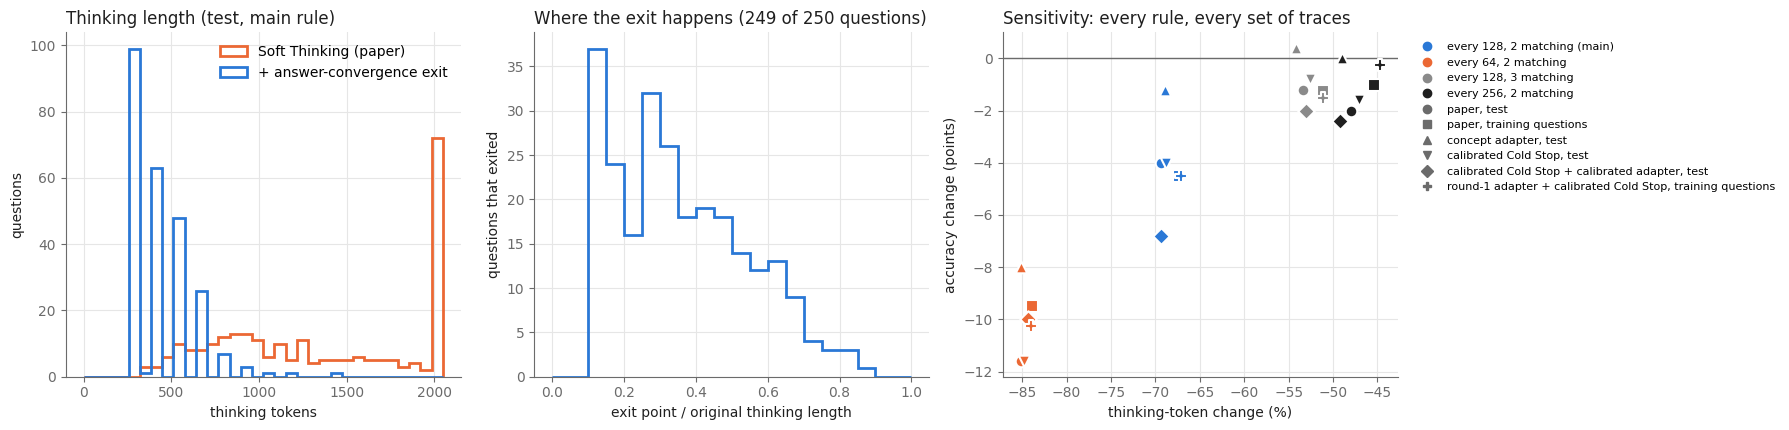

In [18]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.titlelocation": "left", "axes.titlecolor": INK})
GRAY = "#8a8a8a"

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))

ax = axes[0]
bins = np.linspace(0, CFG.max_think_tokens, 33)
ax.hist(pm["orig_tokens"], bins=bins, histtype="step", linewidth=2, color=ORANGE, label="Soft Thinking (paper)")
ax.hist(pm["tokens"], bins=bins, histtype="step", linewidth=2, color=BLUE, label="+ answer-convergence exit")
ax.set_xlabel("thinking tokens"); ax.set_ylabel("questions"); ax.set_title("Thinking length (test, main rule)")
ax.legend(frameon=False)

ax = axes[1]
ex = pm[pm["exited"]]
frac = ex["tokens"] / ex["orig_tokens"].clip(lower=1)
ax.hist(frac, bins=np.linspace(0, 1, 21), histtype="step", linewidth=2, color=BLUE)
ax.set_xlabel("exit point / original thinking length"); ax.set_ylabel("questions that exited")
ax.set_title(f"Where the exit happens ({len(ex)} of {len(pm)} questions)")

ax = axes[2]
markers = dict(zip(EE.keys(), ("o", "s", "^", "v", "D", "P")))
colors = {r: c for r, c in zip(results_table["rule"].unique(), (BLUE, ORANGE, GRAY, INK))}
for _, row in results_table.iterrows():
    ax.scatter(100 * row["token change"], 100 * (row["accuracy (exit)"] - row["accuracy (no exit)"]), s=70,
               marker=markers.get(row["traces"], "o"), color=colors[row["rule"]], edgecolors="white", linewidths=1.5, zorder=3)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xlabel("thinking-token change (%)"); ax.set_ylabel("accuracy change (points)")
ax.set_title("Sensitivity: every rule, every set of traces")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color=c, label=r) for r, c in colors.items()] +
                  [Line2D([], [], marker=m, linestyle="", color=MUTED, label=t) for t, m in markers.items()],
          frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout(); plt.show()

In [19]:
# Questions the main rule got wrong after exiting early (originally correct): what did the probes say?
by_id = {r["id"]: r for r in paper_test}
lost = pm[pm["orig_correct"] & ~pm["correct"]]
rows = []
for i, row in lost.head(8).iterrows():
    rows.append({"question": i, "gold": row["gold"], "early answer": row["pred"],
                 "exit at": int(row["tokens"]), "original length": int(row["orig_tokens"])})
pd.DataFrame(rows) if rows else print("No originally-correct question was lost by the main rule.")

,question,gold,early answer,exit at,original length
0,8,45.0,0.0,256,2047
1,12,13.0,1.0,512,2047
2,13,18.0,5.0,256,1598
3,86,22.0,1.0,256,2047
4,112,24.0,3.0,256,1715
5,125,10.0,7.0,384,2047
6,139,70.0,4.0,384,2047
7,153,48.0,30.0,768,1352


---
# Part 6: Conclusion

In [20]:
c = comparisons
main_paper = results_table[(results_table["traces"] == "paper, test") & (results_table["rule"] == MAIN)].iloc[0]
lines = [f"ANSWER-CONVERGENCE EXIT ({MAIN}) on Soft Thinking (paper) traces, {int(main_paper['questions'])} test questions",
         f"  exit rate {main_paper['exit rate']:.0%} | accuracy {main_paper['accuracy (no exit)']:.1%} -> {main_paper['accuracy (exit)']:.1%} "
         f"(lost {main_paper['lost']}, gained {main_paper['gained']}, McNemar p = {main_paper['McNemar p']:.3f})",
         f"  thinking tokens {main_paper['thinking tokens (no exit)']:.0f} -> {main_paper['thinking tokens (exit)']:.0f} "
         f"({main_paper['token change']:+.1%}; {main_paper['token change incl. probes']:+.1%} incl. probes), Wilcoxon p = {main_paper['tokens Wilcoxon p']:.2g}"]
lines.append("MAIN RULE ON EVERY SET OF TRACES")
for _, t in results_table[results_table["rule"] == MAIN].iterrows():
    lines.append(f"  {t['traces']:<58} n={int(t['questions']):3d} | acc {t['accuracy (no exit)']:.1%} -> {t['accuracy (exit)']:.1%} "
                 f"(lost {t['lost']}, gained {t['gained']}, p = {t['McNemar p']:.3f}) | tokens {t['token change']:+.1%} "
                 f"({t['token change incl. probes']:+.1%} incl. probes, p = {t['tokens Wilcoxon p']:.2g})")
if ALL_OURS:
    allours = c.iloc[-1]
    lines.append(f"ALL OURS ({ALL_OURS}) vs PAPER: accuracy {allours['accuracy change']*100:+.1f} points "
                 f"(McNemar p = {allours['McNemar p']:.3f}), thinking tokens {allours['token change']:+.1%} "
                 f"({allours['token change incl. probes']:+.1%} incl. probes), Wilcoxon p = {allours['tokens Wilcoxon p']:.2g}")
print("\n".join(lines))

results_table.to_csv(f"{OUT_DIR}/early_exit_rules.csv", index=False)
summary.to_csv(f"{OUT_DIR}/early_exit_summary.csv")
comparisons.to_csv(f"{OUT_DIR}/early_exit_comparisons.csv")
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump({"run_mode": RUN_MODE, "model": MODEL_NAME, "inputs": [NB1_DIR, NB2_DIR, NB3_DIR, NB4_DIR], **asdict(CFG)}, f, indent=2)
print("\nsaved:", sorted(os.listdir(OUT_DIR)))

ANSWER-CONVERGENCE EXIT (every 128, 2 matching (main)) on Soft Thinking (paper) traces, 250 test questions
  exit rate 100% | accuracy 89.2% -> 85.2% (lost 14, gained 4, McNemar p = 0.031)
  thinking tokens 1341 -> 411 (-69.4%; -66.3% incl. probes), Wilcoxon p = 1.3e-42
MAIN RULE ON EVERY SET OF TRACES
  paper, test                                                n=250 | acc 89.2% -> 85.2% (lost 14, gained 4, p = 0.031) | tokens -69.4% (-66.3% incl. probes, p = 1.3e-42)
  paper, training questions                                  n=400 | acc 89.2% -> 84.8% (lost 24, gained 6, p = 0.001) | tokens -67.3% (-64.1% incl. probes, p = 8.1e-67)
  concept adapter, test                                      n=250 | acc 87.6% -> 86.4% (lost 12, gained 9, p = 0.664) | tokens -68.9% (-65.9% incl. probes, p = 1.3e-42)
  calibrated Cold Stop, test                                 n=250 | acc 89.2% -> 85.2% (lost 14, gained 4, p = 0.031) | tokens -68.8% (-65.7% incl. probes, p = 1.3e-42)
  calibrated Col

**Interpretation.**

* **What the rule exploits.** Notebook 3 showed that most thinking happens after the answer is already written. An answer-aware signal can stop there; an entropy-based one cannot.
* **How to read the main result.**
  * **Efficiency gain:** a large token reduction (Wilcoxon) with a non-significant accuracy change (McNemar).
  * **Speed–accuracy trade-off:** a significant accuracy loss alongside the token reduction. The "lost" table shows whether the model committed early to a wrong answer.
* **Probe overhead** is reported separately and is small relative to the thinking it removes: each probe costs about 20 tokens of compute, and the main rule probes every 128 steps.
* **The training-question traces** are a larger second sample. Since the rule is fixed, nothing is fitted on them.

**Limitations.**

* Results come from exact replay of saved traces. This relies on deterministic decoding, verified in Notebook 3 and by the reproduction check above.
* The answer probe is designed for numeric answers (GSM8K).
* The rule parameters are fixed, not tuned.
* The idea itself comes from chain-of-thought work; our contribution is applying and evaluating it for Soft Thinking.